
# Question 1: Rwanda Maize Yield Dataset Preparation

## Stage 4: Clean and Pre-process the Data

Group Number: Group 2

Members: Armand Ikirezi and Mariam Nyirarukundo

Scenario: Predicting Maize Yield for Farmer Cooperatives in Rwanda

Stakeholder: Maize Cooperative Support Unit (MCSU)

### Objective

To clean and preprocess the supplied maize yield dataset by handling missing values, duplicates, invalid values, outliers, categorical variables and numerical features.

The dataset will be divided into training, validation and test sets using a fixed random seed.

### Target Variable

`yield_t_ha` – maize yield measured in tonnes per hectare.

**Important:** The original raw dataset will remain unchanged. All cleaning operations will be performed programmatically and documented in a Cleaning Log.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Define project directory
project_dir = Path(r"D:\MYProject\ML_Element1")

# Locate original dataset
data_path = (
    project_dir
    / "q1_maize_yield"
    / "data"
    / "raw"
    / "maize_yield_rwanda_rw.csv"
)

# Load original data
df = pd.read_csv(data_path)

# Keep a copy of the original data for comparison
df_original = df.copy(deep=True)

print("Original dataset loaded successfully!")
print("Original dataset shape:", df.shape)


Original dataset loaded successfully!
Original dataset shape: (1426, 20)


In [3]:

print("BEFORE CLEANING")
print("================")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate record IDs:",
      df["record_id"].duplicated().sum())


BEFORE CLEANING
Dataset shape: (1426, 20)

Missing values:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64

Duplicate rows: 0

Duplicate record IDs: 0


In [4]:

# Initialize the cleaning log
cleaning_log = []

def log_cleaning_step(
    operation,
    affected_column,
    records_affected,
    before,
    after,
    justification
):
    cleaning_log.append({
        "Operation": operation,
        "Affected_Column": affected_column,
        "Records_Affected": records_affected,
        "Before": str(before),
        "After": str(after),
        "Justification": justification
    })

print("Cleaning Log initialized successfully.")


Cleaning Log initialized successfully.


In [5]:

# Check duplicate rows before removal
duplicates_before = df.duplicated().sum()

# Remove exact duplicate rows, if any
df = df.drop_duplicates().copy()

duplicates_after = df.duplicated().sum()

# Record the operation
log_cleaning_step(
    operation="Remove exact duplicate rows",
    affected_column="All columns",
    records_affected=duplicates_before,
    before=f"{duplicates_before} duplicate rows",
    after=f"{duplicates_after} duplicate rows",
    justification="Exact duplicate records should not be counted as separate observations."
)

print("Duplicate rows before:", duplicates_before)
print("Duplicate rows after:", duplicates_after)
print("Dataset shape after duplicate check:", df.shape)


Duplicate rows before: 0
Duplicate rows after: 0
Dataset shape after duplicate check: (1426, 20)


In [6]:

# Define conservative invalid-value rules
invalid_rules = {
    "rainfall_mm": lambda s: s < 0,
    "soil_ph": lambda s: (s < 0) | (s > 14),
    "npk_kg_ha": lambda s: s < 0,
    "urea_kg_ha": lambda s: s < 0,
    "manure_t_ha": lambda s: s < 0,
    "farm_area_ha": lambda s: s <= 0,
    "plant_density_per_ha": lambda s: s <= 0,
    "yield_t_ha": lambda s: s <= 0
}

# Count and replace invalid values with NaN
for column, rule in invalid_rules.items():

    invalid_mask = rule(df[column])

    affected = int(invalid_mask.sum())

    if affected > 0:

        before_values = df.loc[invalid_mask, column].tolist()

        df.loc[invalid_mask, column] = np.nan

        log_cleaning_step(
            operation="Replace invalid values with missing values",
            affected_column=column,
            records_affected=affected,
            before=before_values[:10],
            after="NaN",
            justification="Values violate the selected domain rule and require investigation or appropriate imputation."
        )

    print(f"{column}: {affected} invalid values identified")


rainfall_mm: 0 invalid values identified
soil_ph: 0 invalid values identified
npk_kg_ha: 0 invalid values identified
urea_kg_ha: 0 invalid values identified
manure_t_ha: 0 invalid values identified
farm_area_ha: 0 invalid values identified
plant_density_per_ha: 0 invalid values identified
yield_t_ha: 0 invalid values identified


In [7]:

print("Missing values after invalid-value checks:")
print(df.isnull().sum())

print("\nTotal missing cells:", df.isnull().sum().sum())


Missing values after invalid-value checks:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64

Total missing cells: 39


In [8]:

# Identify text columns
categorical_columns = df.select_dtypes(
    include=["str", "object"]
).columns.tolist()

# Standardize leading and trailing spaces
for column in categorical_columns:

    before_unique = df[column].nunique(dropna=True)

    df[column] = df[column].str.strip()

    after_unique = df[column].nunique(dropna=True)

    print(
        f"{column}: "
        f"{before_unique} unique values before, "
        f"{after_unique} after"
    )

    if before_unique != after_unique:

        log_cleaning_step(
            operation="Remove leading and trailing whitespace",
            affected_column=column,
            records_affected="Values with whitespace require inspection",
            before=before_unique,
            after=after_unique,
            justification="Standardizes accidental whitespace without changing category meaning."
        )


record_id: 1426 unique values before, 1426 after
season: 3 unique values before, 3 after
province: 5 unique values before, 5 after
district: 30 unique values before, 30 after
soil_type: 5 unique values before, 5 after
seed_variety: 6 unique values before, 6 after
farming_practice: 2 unique values before, 2 after
irrigation: 2 unique values before, 2 after


In [9]:

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))



record_id
record_id
RW-MZ-00001    1
RW-MZ-00002    1
RW-MZ-00003    1
RW-MZ-00004    1
RW-MZ-00005    1
              ..
RW-MZ-01422    1
RW-MZ-01423    1
RW-MZ-01424    1
RW-MZ-01425    1
RW-MZ-01426    1
Name: count, Length: 1426, dtype: int64

season
season
A    600
B    600
C    226
Name: count, dtype: int64

province
province
Southern    388
Western     348
Eastern     328
Northern    230
Kigali      132
Name: count, dtype: int64

district
district
Karongi       56
Nyanza        54
Huye          52
Nyamasheke    52
Gicumbi       50
Kirehe        50
Nyabihu       50
Ruhango       50
Rutsiro       50
Gisagara      48
Kamonyi       48
Kayonza       48
Nyagatare     48
Nyamagabe     48
Rulindo       48
Rusizi        48
Rwamagana     48
Bugesera      46
Gakenke       46
Gatsibo       46
Ngororero     46
Nyarugenge    46
Rubavu        46
Kicukiro      44
Muhanga       44
Musanze       44
Nyaruguru     44
Burera        42
Gasabo        42
Ngoma         42
Name: count, dtype: int64

soi

In [10]:

# Count missing target values
missing_target_before = df["yield_t_ha"].isna().sum()

# Remove records without a known target
df = df.dropna(subset=["yield_t_ha"]).copy()

missing_target_after = df["yield_t_ha"].isna().sum()

log_cleaning_step(
    operation="Remove rows with missing target",
    affected_column="yield_t_ha",
    records_affected=int(missing_target_before),
    before=missing_target_before,
    after=missing_target_after,
    justification="Supervised regression requires a known target value for each retained observation."
)

print("Missing targets before:", missing_target_before)
print("Missing targets after:", missing_target_after)
print("Dataset shape:", df.shape)


Missing targets before: 0
Missing targets after: 0
Dataset shape: (1426, 20)



The IQR method identified potential outliers during Stage 3. These observations were not automatically removed because extreme agricultural measurements may represent genuine farm conditions.

Only values that violate the selected domain rules are treated as invalid. Plausible extreme observations are retained to preserve the original variability of the dataset.

Outlier capping or removal will only be applied if further evidence confirms that particular values are erroneous.


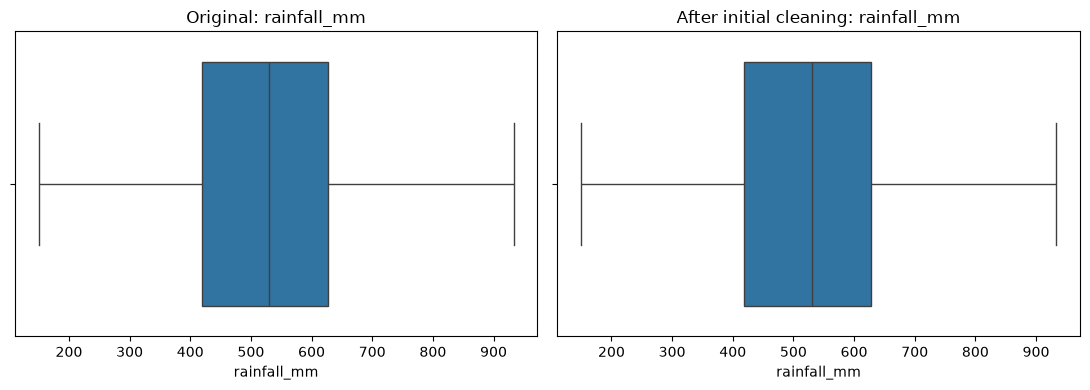

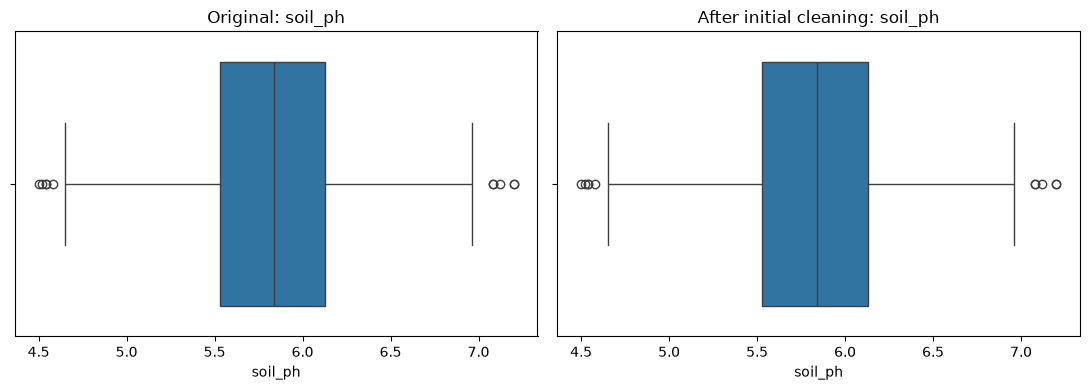

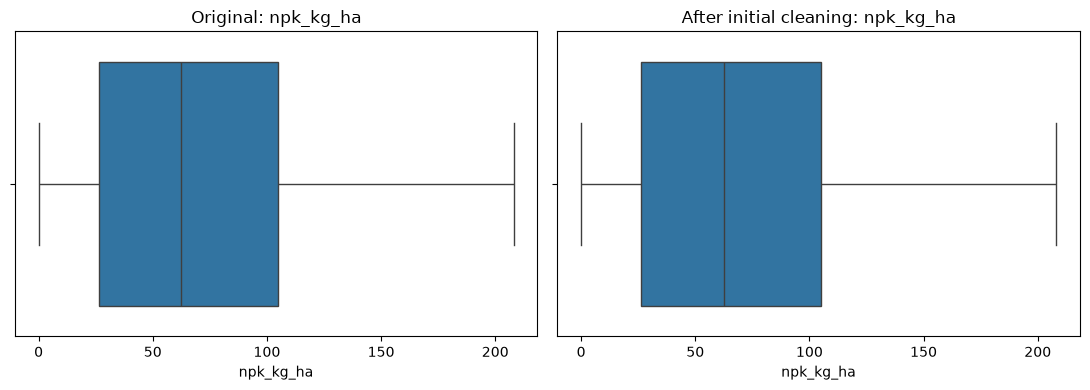

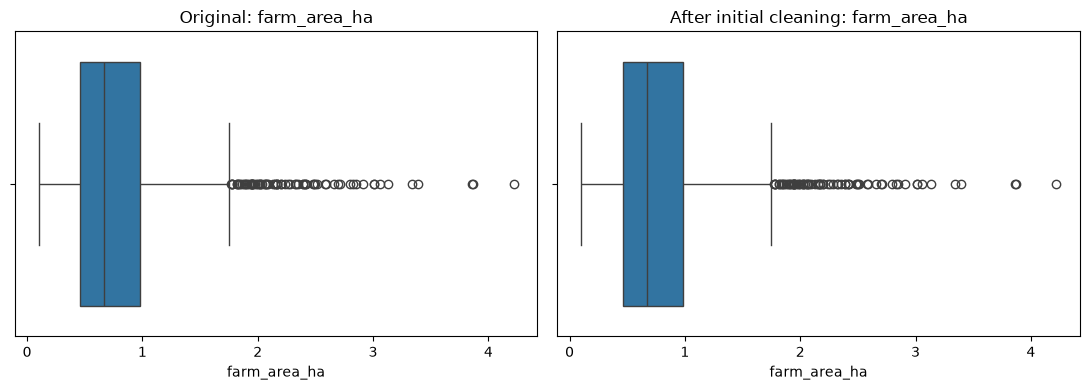

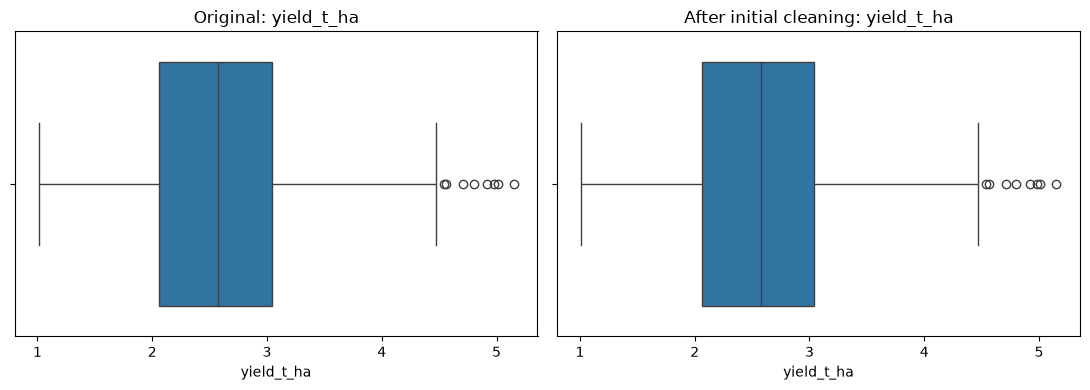

In [11]:

# Compare original and currently cleaned numerical distributions
columns_to_compare = [
    "rainfall_mm",
    "soil_ph",
    "npk_kg_ha",
    "farm_area_ha",
    "yield_t_ha"
]

for column in columns_to_compare:

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    sns.boxplot(
        x=df_original[column],
        ax=axes[0]
    )
    axes[0].set_title(f"Original: {column}")

    sns.boxplot(
        x=df[column],
        ax=axes[1]
    )
    axes[1].set_title(f"After initial cleaning: {column}")

    plt.tight_layout()
    plt.show()


In [12]:

# Correct the year data type
df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
).astype("Int64")

# Ensure the target is numeric
df["yield_t_ha"] = pd.to_numeric(
    df["yield_t_ha"],
    errors="coerce"
)

# Verify data types
print(df.dtypes)


record_id                   str
year                      Int64
season                      str
province                    str
district                    str
altitude_m                int64
rainfall_mm             float64
avg_temp_c              float64
soil_ph                 float64
soil_type                   str
seed_variety                str
farming_practice            str
npk_kg_ha               float64
urea_kg_ha              float64
manure_t_ha             float64
plant_density_per_ha      int64
farm_area_ha            float64
irrigation                  str
pest_incidence_index    float64
yield_t_ha              float64
dtype: object


In [13]:

from sklearn.model_selection import train_test_split

# Define target
target_column = "yield_t_ha"

# Exclude the target and record identifier from input features
X = df.drop(
    columns=[target_column, "record_id"]
)

y = df[target_column]

print("Input features:", X.shape)
print("Target:", y.shape)


Input features: (1426, 18)
Target: (1426,)


In [14]:

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Second split: divide remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("TRAINING SET")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDATION SET")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTEST SET")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTotal records:", len(X_train) + len(X_val) + len(X_test))


TRAINING SET
X_train: (998, 18)
y_train: (998,)

VALIDATION SET
X_val: (214, 18)
y_val: (214,)

TEST SET
X_test: (214, 18)
y_test: (214,)

Total records: 1426


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns from training data
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully.")


Numerical features:
['year', 'altitude_m', 'rainfall_mm', 'avg_temp_c', 'soil_ph', 'npk_kg_ha', 'urea_kg_ha', 'manure_t_ha', 'plant_density_per_ha', 'farm_area_ha', 'pest_incidence_index']

Categorical features:
['season', 'province', 'district', 'soil_type', 'seed_variety', 'farming_practice', 'irrigation']

Preprocessing pipeline created successfully.


In [16]:

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test using training-fitted preprocessing
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training transformed shape:", X_train_processed.shape)
print("Validation transformed shape:", X_val_processed.shape)
print("Testing transformed shape:", X_test_processed.shape)


Training transformed shape: (998, 64)
Validation transformed shape: (214, 64)
Testing transformed shape: (214, 64)


In [17]:

# Get the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Display the processed training features
X_train_encoded = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

display(X_train_encoded.head())


,num__year,num__altitude_m,num__rainfall_mm,num__avg_temp_c,num__soil_ph,num__npk_kg_ha,num__urea_kg_ha,num__manure_t_ha,num__plant_density_per_ha,num__farm_area_ha,...,cat__seed_variety_Local,cat__seed_variety_PAN691,cat__seed_variety_RHM104,cat__seed_variety_WH505,cat__seed_variety_ZM607,cat__seed_variety_ZM621,cat__farming_practice_Improved,cat__farming_practice_Traditional,cat__irrigation_No,cat__irrigation_Yes
390,-0.860897,0.772074,0.014741,-0.430069,-1.733868,-1.391477,-0.216704,-0.209508,-1.987868,-1.338987,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
573,-0.165490,0.961328,1.530772,-0.976832,0.254993,-0.854603,0.587311,-0.953178,0.576370,5.997153,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
807,0.182213,-1.647674,-1.247534,2.060740,0.735063,-0.704877,-0.261910,-0.187419,-1.918933,-0.539036,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1228,1.225323,0.141227,0.166995,-0.551572,-0.247938,-1.391477,-1.204771,0.924404,-0.806228,-0.519525,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
585,-0.165490,0.055612,0.191720,0.116694,1.146551,-0.587235,-0.736569,0.210187,-1.619497,0.768202,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [18]:

# Define output directories
interim_dir = (
    project_dir
    / "q1_maize_yield"
    / "data"
    / "interim"
)

docs_dir = (
    project_dir
    / "q1_maize_yield"
    / "docs"
)

interim_dir.mkdir(parents=True, exist_ok=True)
docs_dir.mkdir(parents=True, exist_ok=True)

print("Output directories are ready.")


Output directories are ready.


In [19]:

cleaned_data_path = interim_dir / "maize_yield_cleaned.csv"

df.to_csv(cleaned_data_path, index=False)

print("Cleaned dataset saved:")
print(cleaned_data_path)


Cleaned dataset saved:
D:\MYProject\ML_Element1\q1_maize_yield\data\interim\maize_yield_cleaned.csv


In [20]:

# Convert transformed arrays into DataFrames
X_train_final = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_final = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

X_test_final = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

# Add the target variable
train_final = X_train_final.copy()
train_final[target_column] = y_train

validation_final = X_val_final.copy()
validation_final[target_column] = y_val

test_final = X_test_final.copy()
test_final[target_column] = y_test

# Save all three datasets
train_final.to_csv(
    interim_dir / "maize_yield_train.csv",
    index=False
)

validation_final.to_csv(
    interim_dir / "maize_yield_validation.csv",
    index=False
)

test_final.to_csv(
    interim_dir / "maize_yield_test.csv",
    index=False
)

print("Training, validation and test datasets saved successfully!")


Training, validation and test datasets saved successfully!


In [21]:

import joblib

pipeline_path = interim_dir / "maize_preprocessing_pipeline.joblib"

joblib.dump(preprocessor, pipeline_path)

print("Preprocessing pipeline saved:")
print(pipeline_path)


Preprocessing pipeline saved:
D:\MYProject\ML_Element1\q1_maize_yield\data\interim\maize_preprocessing_pipeline.joblib


In [22]:

# Convert cleaning log into a DataFrame
cleaning_log_df = pd.DataFrame(cleaning_log)

# Save cleaning log
cleaning_log_path = docs_dir / "cleaning_log.csv"

cleaning_log_df.to_csv(
    cleaning_log_path,
    index=False
)

display(cleaning_log_df)

print("Cleaning Log saved successfully!")
print(cleaning_log_path)


,Operation,Affected_Column,Records_Affected,Before,After,Justification
0,Remove exact duplicate rows,All columns,0,0 duplicate rows,0 duplicate rows,Exact duplicate records should not be counted ...
1,Remove rows with missing target,yield_t_ha,0,0,0,Supervised regression requires a known target ...


Cleaning Log saved successfully!
D:\MYProject\ML_Element1\q1_maize_yield\docs\cleaning_log.csv


In [23]:

print("FINAL CLEANING SUMMARY")
print("======================")

print("\nBEFORE CLEANING")
print("Original shape:", df_original.shape)
print("Original missing cells:", df_original.isnull().sum().sum())
print("Original duplicate rows:", df_original.duplicated().sum())

print("\nAFTER INITIAL CLEANING")
print("Cleaned shape:", df.shape)
print("Remaining missing cells:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

print("\nFINAL SPLIT SIZES")
print("Training records:", len(train_final))
print("Validation records:", len(validation_final))
print("Testing records:", len(test_final))

print("\nTRANSFORMED FEATURE COUNTS")
print("Training features:", X_train_final.shape[1])
print("Validation features:", X_val_final.shape[1])
print("Testing features:", X_test_final.shape[1])


FINAL CLEANING SUMMARY

BEFORE CLEANING
Original shape: (1426, 20)
Original missing cells: 39
Original duplicate rows: 0

AFTER INITIAL CLEANING
Cleaned shape: (1426, 20)
Remaining missing cells: 39
Remaining duplicate rows: 0

FINAL SPLIT SIZES
Training records: 998
Validation records: 214
Testing records: 214

TRANSFORMED FEATURE COUNTS
Training features: 64
Validation features: 64
Testing features: 64


The original maize yield dataset was subjected to duplicate checking, invalid-value handling and categorical standardization. 
Numerical and categorical missing values were handled through a preprocessing pipeline fitted on the training set only. 
The dataset was divided into training, validation and test sets using a fixed random seed to ensure reproducibility. 
The original raw file was preserved.